# Calibration, decision bands, explanations and fairness

Phase 5. The model stops being a ranking and becomes a decision: every
activation is auto-released, sent to a human, or refused.

**What changed in how results are reported.** Seed 42 is no longer the headline.
Every number here is a mean across seeds 7, 42, 101 and 2024 with the
seed-level spread beside it. Fold-level spread appears only as a secondary
figure, and it understates uncertainty: `StratifiedGroupKFold` orders groups by
size, so fold 0 always carries the heaviest agents and the folds are not
exchangeable.

**What changed in the model.** The matched-strength sweep in Phase 4 put every
resampling method within 0.004 PR-AUC of every other against a fold standard
deviation of 0.037, with no handling scoring highest. The chosen model is
therefore XGBoost on the T7 feature set with **no resampling and no class
weighting**. The pre-registered Phase 3 choice (SMOTE at a minority ratio of
0.30) is trained and reported alongside: it scores 0.703 against 0.712, a gap of
0.009 against a seed-level spread of 0.034, so the deviation costs nothing
measurable and the sweep's conclusion holds.

**What changed in the training loop.** Each fold's training split is divided by
agent: the model is fitted on one part and the probability calibrator on the
other, which the model has never seen. The model therefore trains on about three
quarters of the rows it used in Phase 4, which is the price of an honest
calibrator. PR-AUC here (0.712) is not comparable with the Phase 4 seed-42
figure (0.781): different seeds, fewer training rows, one repeat instead of
three.

Nothing here is tuned toward a metric. `config/costs.yaml` was written before
the bands were optimised, and the calibration method was chosen by a rule fixed
in advance.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

OUT = REPO_ROOT / "outputs"
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 150)

read = lambda name: pd.read_csv(OUT / f"{name}.csv")
calibration = read("calibration_summary")
choice = read("calibration_choice")
curves = read("calibration_reliability_curves")
auto_release = read("auto_release_summary")
auto_release_gap = read("auto_release_t0_vs_t7")
operating = read("band_operating_point")
surface = read("band_cost_surface")
sensitivity = read("band_sensitivity")
staffing = read("band_staffing")
baselines = read("band_baselines")
costs = read("cost_matrix")
shap_global = read("shap_global_importance")
shap_typology = read("shap_importance_by_typology")
shap_shares = read("shap_agent_history_share")
shap_cases = read("shap_worked_cases")
fair_honesty = read("fairness_bands_by_honesty")
fair_situation = read("fairness_bands_by_situation")
fair_delay = read("fairness_expected_delay")
fair_queue = read("fairness_queue")
audit_stability = read("lookalike_audit_stability")
seed_summary = read("multiseed_seed_summary")

METHOD = choice["chosen_method"].iloc[0]
RELEASE = float(operating["release_threshold"].iloc[0])
REJECT = float(operating["reject_threshold"].iloc[0])

SURFACE, INK, INK_2, MUTED, GRID, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 2.0, "legend.frameon": False, "font.size": 10, "axes.titlesize": 11,
})
print(f"seeds: {sorted(seed_summary['seed'])}")
print(f"calibration: {METHOD}; bands: release <= {RELEASE:.4f}, reject > {REJECT:.4f}")

seeds: [7, 42, 101, 2024]
calibration: isotonic; bands: release <= 0.2059, reject > 0.3980


## The four datasets

In [2]:
seed_summary.round(4)

,seed,activations,realised_fraud_rate,days,mean_daily_activations,mean_commission_value_kes
0,7,89325,0.0701,180,496.250,81.3701
1,42,90533,0.0735,180,502.961,81.1948
2,101,91944,0.0723,180,510.800,81.3951
3,2024,94675,0.0716,180,525.972,81.2194


## The lookalike audit, now across every seed

The standing rule from the Phase 4 review, now in CLAUDE.md: a missing
counterpart is real only if it is stable across realisations. A signature
flagged at one seed and not the others is noise and must not be fixed.

**Result: no defects.** No signature is flagged at all four seeds. The sim
farming device-sharing flag that surfaced in Phase 4 appears at exactly one seed
of four, with a legitimate share ranging from 1.0% to 4.2% depending on the
draw. Under the new rule it is noise, and it is not fixed.

In [3]:
flagged = audit_stability[audit_stability["seeds_flagged"] > 0]
print(f"signatures flagged at one or more of the {int(audit_stability['seeds_audited'].iloc[0])} seeds: {len(flagged)}")
print(f"defects (flagged at every seed): {(audit_stability['verdict'].str.startswith('defect')).sum()}")
flagged[["typology", "feature", "seeds_flagged", "legitimate_share_min", "legitimate_share_mean",
         "legitimate_share_max", "fraud_purity_mean", "verdict"]].round(5)

signatures flagged at one or more of the 4 seeds: 1
defects (flagged at every seed): 0


,typology,feature,seeds_flagged,legitimate_share_min,legitimate_share_mean,legitimate_share_max,fraud_purity_mean,verdict
0,sim_farming,device_shared_agent_count_30d,1,0.00998,0.02787,0.04196,0.3179,noise: flagged at some seeds only


## The cost matrix

All costs in units of one agent commission, so the optimisation holds whatever a
commission is worth. `review` and `review_capacity_daily_share` are computed
from their parts rather than assumed.

Two things to carry into everything downstream:

- **The computed review cost is 0.576, not the 0.45 in the brief.** The
  components given (9 minutes, KSh 55,000 a month, 176 hours, KSh 312.50 an
  hour) divided by the generator's implied commission value of KSh 81.34
  produce 0.576. It sits inside the stated 0.25 to 0.70 range, the computed
  value is what the optimisation uses, and the sensitivity analysis sweeps the
  whole range, so both values are covered.
- **`commission_value_kes` is the least-sourced number in the file.** It comes
  from the generator's assumed escrow distribution, not from an industry
  partner, and the review cost scales inversely with it. If a real commission is
  worth more than KSh 81, review is cheaper than modelled and the review band
  should be wider than the one chosen below.

In [4]:
costs.round(4)

,quantity,value,unit,derivation,stated_in_brief
0,commission,1.0000,commission,the unit of account,NaN
1,false_negative,2.5000,commissions,"commission paid on non-existent work, unrecove...",2.5
2,false_positive,1.0000,commissions,review cost plus P(churn after an unjust delay...,NaN
3,loaded_hourly_rate_kes,312.5000,KSh per hour,55000 KSh per month / 176 hours,NaN
4,commission_value_kes,81.3400,KSh,generator mean escrow times commission_rate; l...,NaN
5,review,0.5763,commissions,9 min / 60 * 312.50 KSh per hour / 81.34 KSh p...,NaN
6,reviews_per_reviewer_day,40.0000,reviews,6 productive hours * 60 / 9 min,NaN
7,mean_daily_activations,508.9960,activations,mean across the seeds of activations divided b...,NaN
8,review_capacity_daily_share,0.0786,share of volume,1 reviewer(s) * 40 reviews / 509 activations p...,NaN


## Part B: calibration

The bands are probability cutoffs, so the scores feeding them have to mean what
they say. Each calibrator is fitted inside the training window on agents the
model never saw, and never on test data. Expected calibration error uses
equal-count bins, because calibrated fraud probabilities pile up near zero and
equal-width bins would put almost everything in the first one.

**Chosen: isotonic**, by a rule fixed before the numbers were seen (lowest ECE,
Brier breaking a tie inside one seed-level standard deviation).

- Isotonic more than halves ECE against the raw scores: **0.0067 against 0.0105**.
- **Platt scaling makes calibration worse than doing nothing** (ECE 0.0212). The sigmoid is too rigid for this score distribution, which is dense near zero with a long thin tail.
- The raw scores were already reasonably calibrated, which is what an XGBoost model fitted without resampling should look like: nothing has distorted the class balance it was trained on.

**Part B5.** PR-AUC moves by -0.006 (0.718 to 0.712), against a fold-level
standard deviation of 0.053. Both mappings are monotone, so ranking cannot
change except through ties; isotonic creates ties, which is the entire effect.
Nothing to investigate.

In [5]:
calibration[["method", "brier_mean", "brier_sd_across_seeds", "ece_mean", "ece_sd_across_seeds",
             "pr_auc_mean", "pr_auc_sd_across_seeds", "pr_auc_sd_across_folds",
             "mean_predicted", "observed_fraud_rate"]].round(5)

,method,brier_mean,brier_sd_across_seeds,ece_mean,ece_sd_across_seeds,pr_auc_mean,pr_auc_sd_across_seeds,pr_auc_sd_across_folds,mean_predicted,observed_fraud_rate
0,isotonic,0.03513,0.00179,0.00671,0.00285,0.71199,0.03387,0.05334,0.06718,0.07283
1,sigmoid,0.03625,0.00182,0.02124,0.00154,0.71172,0.03296,0.05129,0.06937,0.07283
2,uncalibrated,0.03514,0.00169,0.01045,0.00436,0.71832,0.03213,0.05129,0.06283,0.07283


In [6]:
choice.T

,0
chosen_method,isotonic
rule,lowest ECE; Brier breaks ties within one seed-...
ece,0.006707
ece_uncalibrated,0.010445
brier,0.03513
brier_uncalibrated,0.035136
pr_auc,0.711992
pr_auc_uncalibrated,0.718318
pr_auc_change,-0.006325
pr_auc_sd_across_seeds,0.032131


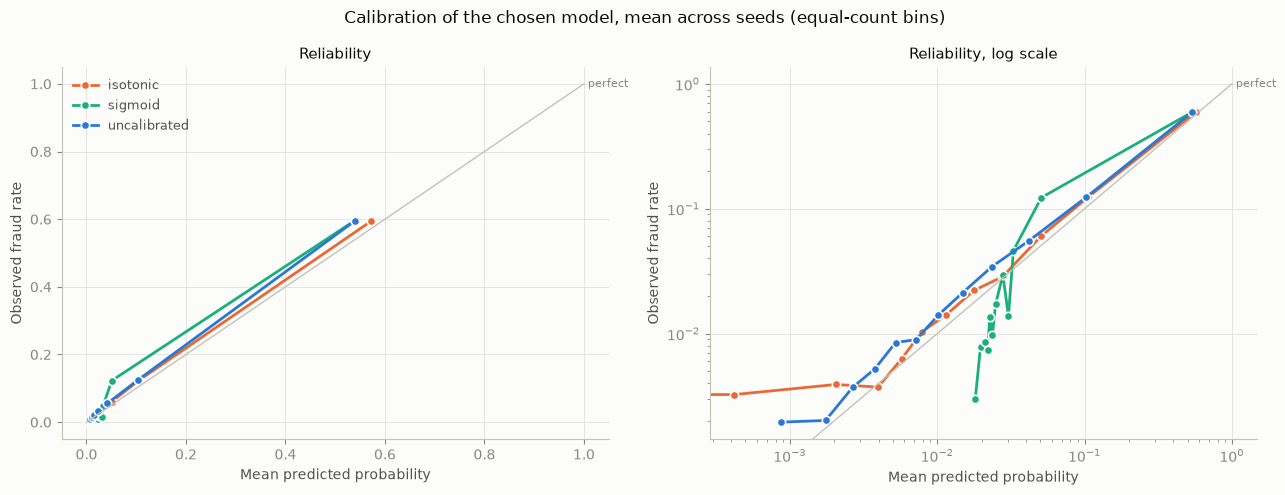

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colour = dict(zip(["uncalibrated", "isotonic", "sigmoid"], SLOTS))
mean_curve = curves.groupby(["method", "bin"])[["mean_predicted", "observed_fraud_rate"]].mean().reset_index()

for axis, (scale, title) in zip(axes, [("linear", "Reliability"), ("log", "Reliability, log scale")]):
    for method, group in mean_curve.groupby("method"):
        group = group.sort_values("mean_predicted")
        axis.plot(group["mean_predicted"], group["observed_fraud_rate"], marker="o", markersize=6,
                  markeredgecolor=SURFACE, markeredgewidth=1.2, color=colour[method], label=method)
    limit = [mean_curve["mean_predicted"].min() * 0.8 if scale == "log" else 0, 1.0]
    axis.plot(limit, limit, color=BASELINE, linewidth=1)
    axis.text(limit[1], limit[1], " perfect", color=MUTED, fontsize=8, va="center")
    axis.set(xscale=scale, yscale=scale, xlabel="Mean predicted probability",
             ylabel="Observed fraud rate", title=title)
axes[0].legend(fontsize=9, loc="upper left")
fig.suptitle(f"Calibration of the chosen model, mean across seeds (equal-count bins)", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "reliability_curves.png", dpi=120)
plt.show()

## Part C: what the hold window actually buys

PR-AUC averages over every threshold, including regions no escrow system would
operate in. Auto-release lives at one end: a payout clears without a human only
where the released set is nearly all genuine.

**Read the 95% row with care.** Prevalence is 7.3%, so releasing every
activation untouched already gives a released set that is 92.7% genuine. The 95%
bar is barely above doing nothing, and both models clear it while releasing
about 97.5% of volume, letting roughly two thirds of all fraud through. It is
not a serious operating point; it is included because it was asked for.

**The 99% row is the real comparison, and the T7 advantage is much larger there
than PR-AUC suggests.**

In [8]:
auto_release[["model", "released_precision_target", "auto_released_share_mean",
              "auto_released_share_sd_across_seeds", "review_queue_share_mean",
              "fraud_released_share_of_all_fraud_mean", "fraud_value_released_share_mean",
              "threshold_mean"]].round(4)

,model,released_precision_target,auto_released_share_mean,auto_released_share_sd_across_seeds,review_queue_share_mean,fraud_released_share_of_all_fraud_mean,fraud_value_released_share_mean,threshold_mean
0,t0_none,0.95,0.9739,0.0050,0.0261,0.6767,0.6764,0.6712
1,t0_none,0.99,0.5739,0.0583,0.4261,0.0824,0.0825,0.0215
2,t7_none,0.95,0.9750,0.0037,0.0250,0.6715,0.6720,0.8244
3,t7_none,0.99,0.7329,0.0400,0.2671,0.1020,0.1018,0.0349


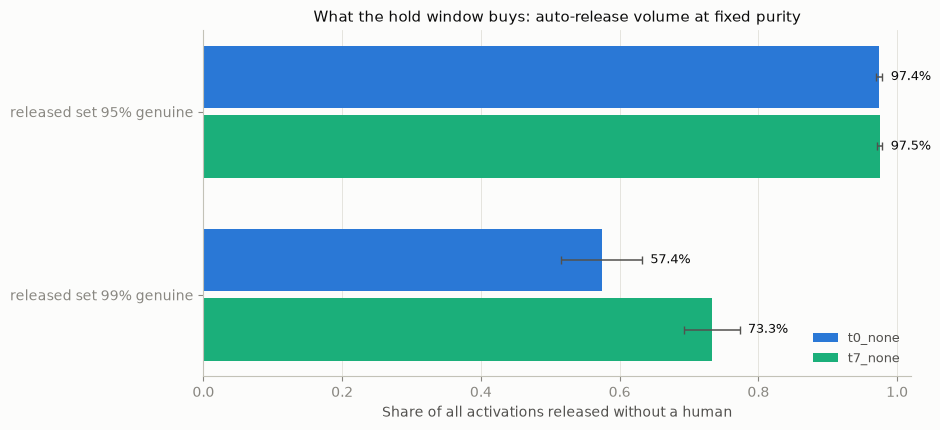

In [9]:
fig, axis = plt.subplots(figsize=(9.5, 4.4))
models = sorted(auto_release["model"].unique())
colour = dict(zip(models, [SLOTS[0], SLOTS[2]]))
targets = sorted(auto_release["released_precision_target"].unique())
base = np.arange(len(targets))[::-1]
for offset, model in zip((0.19, -0.19), models):
    rows = auto_release[auto_release["model"] == model].set_index("released_precision_target").reindex(targets)
    axis.barh(base + offset, rows["auto_released_share_mean"], height=0.34, color=colour[model],
              xerr=rows["auto_released_share_sd_across_seeds"],
              error_kw={"ecolor": INK_2, "elinewidth": 1.1, "capsize": 3}, label=model)
    for y, value, sd in zip(base + offset, rows["auto_released_share_mean"], rows["auto_released_share_sd_across_seeds"]):
        axis.text(value + (sd if np.isfinite(sd) else 0) + 0.012, y, f"{value:.1%}", va="center", fontsize=9, color=INK)
axis.set_yticks(base, [f"released set {t:.0%} genuine" for t in targets])
axis.set(xlabel="Share of all activations released without a human", xlim=(0, 1.02),
         title="What the hold window buys: auto-release volume at fixed purity")
axis.grid(axis="y", visible=False)
axis.legend(fontsize=9, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "auto_release.png", dpi=120)
plt.show()

In [10]:
auto_release_gap.round(4)

,released_precision_target,t7_auto_released_share,t0_auto_released_share,difference,relative_gain,t7_review_queue_share,t0_review_queue_share,t7_fraud_value_released_share,t0_fraud_value_released_share
0,0.95,0.9750,0.9739,0.0011,0.0011,0.0250,0.0261,0.6720,0.6764
1,0.99,0.7329,0.5739,0.1589,0.2769,0.2671,0.4261,0.1018,0.0825


## Part D: where to put the bands

Expected cost per activation is

    P(released and fraudulent) x false_negative
  + P(sent to review)          x review
  + P(rejected and genuine)    x false_positive

A correctly released genuine activation costs nothing. Reviews are assumed to
reach the right answer, so a reviewed activation carries the review cost and no
error cost. **That assumption flatters review**: a real queue makes mistakes,
and every number in this section would move against review if it did not.

The surface is computed per seed and averaged, so the chosen point is best
across four datasets rather than best on one.

In [11]:
operating.T

,0,1
variant,chosen (capacity constrained),unconstrained
release_threshold,0.205882,0.205882
reject_threshold,0.397959,0.397959
expected_cost_per_activation,0.087967,0.087967
expected_cost_sd_across_seeds,0.003821,0.003821
released_share,0.924701,0.924701
review_share,0.025059,0.025059
reject_share,0.05024,0.05024
reject_precision,0.785579,0.785579
reject_recall,0.541315,0.541315


In [12]:
baselines.round(4)

,policy,expected_cost,review_share
0,release everything,0.1820,0
1,review everything,0.5763,1
2,reject everything,0.9272,0


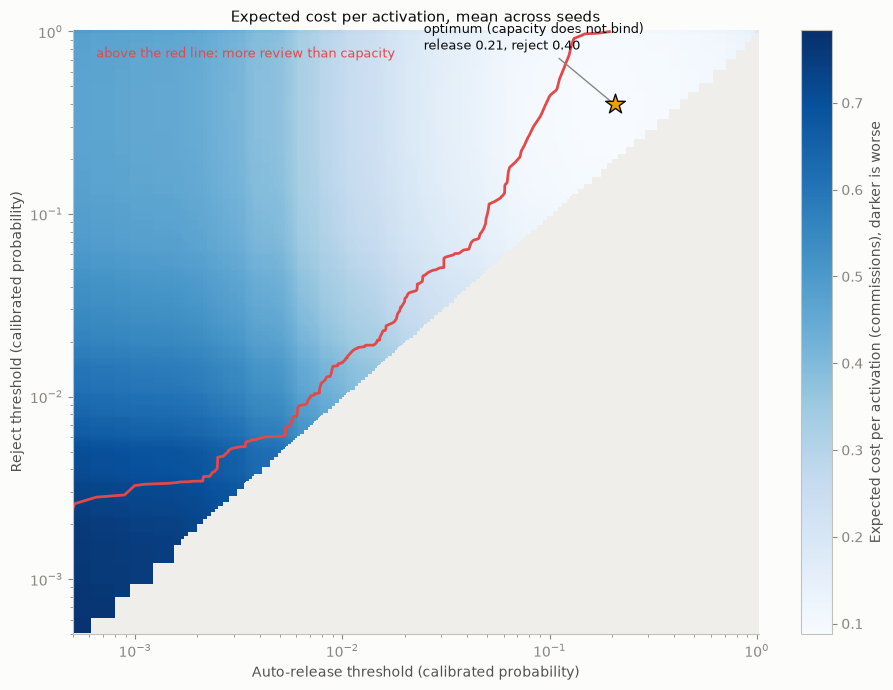

In [13]:
grid_release = np.sort(surface["release_threshold"].unique())
grid_reject = np.sort(surface["reject_threshold"].unique())
pivot = surface.pivot_table(index="reject_threshold", columns="release_threshold", values="expected_cost")
feasible = surface.pivot_table(index="reject_threshold", columns="release_threshold", values="review_share")
capacity = float(operating["capacity_share"].iloc[0])

fig, axis = plt.subplots(figsize=(9.5, 7))
colours = plt.get_cmap("Blues").copy()
colours.set_bad("#efeeea")  # pairs where release > reject: not a valid policy
mesh = axis.pcolormesh(pivot.columns, pivot.index, np.ma.masked_invalid(pivot.to_numpy()),
                       shading="nearest", cmap=colours)
bar = fig.colorbar(mesh, ax=axis)
bar.set_label("Expected cost per activation (commissions), darker is worse", color=INK_2)

# Everything above the red line sends more to review than one reviewer can take.
axis.contourf(feasible.columns, feasible.index, feasible.to_numpy(), levels=[capacity, 1.0],
              colors=["none"], hatches=["////"], alpha=0.0)
axis.contour(feasible.columns, feasible.index, feasible.to_numpy(), levels=[capacity],
             colors=["#e34948"], linewidths=2)
unconstrained = operating[operating["variant"] == "unconstrained"].iloc[0]
same_point = (abs(unconstrained["release_threshold"] - RELEASE) < 1e-12
              and abs(unconstrained["reject_threshold"] - REJECT) < 1e-12)
axis.scatter([RELEASE], [REJECT], s=220, marker="*", color="#eda100", edgecolor=INK, zorder=5)
note = "optimum" if not same_point else "optimum (capacity does not bind)"
axis.annotate(f"{note}\nrelease {RELEASE:.2f}, reject {REJECT:.2f}", xy=(RELEASE, REJECT),
              xytext=(RELEASE * 0.12, REJECT * 2.0), color=INK, fontsize=9,
              arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 1})
if not same_point:
    axis.scatter([unconstrained["release_threshold"]], [unconstrained["reject_threshold"]], s=90,
                 marker="o", color=SURFACE, edgecolor=INK, zorder=5)
axis.text(pivot.columns.min() * 1.3, pivot.index.max() * 0.72,
          "above the red line: more review than capacity", color="#e34948", fontsize=9)
axis.set(xscale="log", yscale="log", xlabel="Auto-release threshold (calibrated probability)",
         ylabel="Reject threshold (calibrated probability)",
         title="Expected cost per activation, mean across seeds")
axis.grid(visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "band_cost_surface.png", dpi=120)
plt.show()

## Part D5: does the answer survive the cost ranges?

Each cost is moved to the bottom and top of its stated range, one at a time,
then all together. **The bands are not stable: they swing hard.**

In [14]:
sensitivity[["scenario", "false_negative", "false_positive", "review", "capacity",
             "release_threshold", "reject_threshold", "release_shift", "reject_shift",
             "review_share", "reject_share", "expected_cost"]].round(4)

,scenario,false_negative,false_positive,review,capacity,release_threshold,reject_threshold,release_shift,reject_shift,review_share,reject_share,expected_cost
0,baseline,2.5,1.0,0.5763,0.0786,0.2059,0.3980,0.0000,0.0000,0.0251,0.0502,0.0880
1,false_negative low (1.5),1.5,1.0,0.5763,0.0786,0.3529,0.3980,0.1471,0.0000,0.0038,0.0502,0.0608
2,false_negative high (4.0),4.0,1.0,0.5763,0.0786,0.1266,0.3980,-0.0793,0.0000,0.0543,0.0502,0.1201
3,false_positive low (0.4),2.5,0.4,0.5763,0.0786,0.1266,0.1266,-0.0793,-0.2713,0.0000,0.1045,0.0693
4,false_positive high (2.5),2.5,2.5,0.5763,0.0786,0.2059,0.7500,0.0000,0.3520,0.0462,0.0291,0.0941
5,review low (0.25),2.5,1.0,0.2500,0.0786,0.1266,0.7500,-0.0793,0.3520,0.0754,0.0291,0.0695
6,review high (0.7),2.5,1.0,0.7000,0.0786,0.2218,0.2218,0.0160,-0.1761,0.0000,0.0705,0.0902
7,capacity low (0.04),2.5,1.0,0.5763,0.0400,0.2059,0.3980,0.0000,0.0000,0.0251,0.0502,0.0880
8,capacity high (0.16),2.5,1.0,0.5763,0.1600,0.2059,0.3980,0.0000,0.0000,0.0251,0.0502,0.0880
9,all costs low,1.5,0.4,0.2500,0.0786,0.1310,0.3529,-0.0749,-0.0450,0.0457,0.0540,0.0471


## Part D6: more reviewers

Nothing changes. The optimum already uses a third of one reviewer's capacity, so
the second and third reviewer have nothing to do. Staffing is not the binding
constraint at this cost matrix; the price of a review is.

In [15]:
staffing.round(4)

,reviewers,capacity_share,release_threshold,reject_threshold,expected_cost,review_share,reject_share,released_share,reject_precision,reject_recall
0,1,0.0786,0.2059,0.398,0.088,0.0251,0.0502,0.9247,0.7856,0.5413
1,2,0.1572,0.2059,0.398,0.088,0.0251,0.0502,0.9247,0.7856,0.5413
2,3,0.2358,0.2059,0.398,0.088,0.0251,0.0502,0.9247,0.7856,0.5413


## Part E: what the model is looking at

SHAP values are computed during training for the chosen model on a sample of
each fold's test rows, so the explanation always belongs to the model that
produced the score. They explain the uncalibrated score; the calibrated
probability is a monotone function of it, so the ordering of reasons is
unaffected.

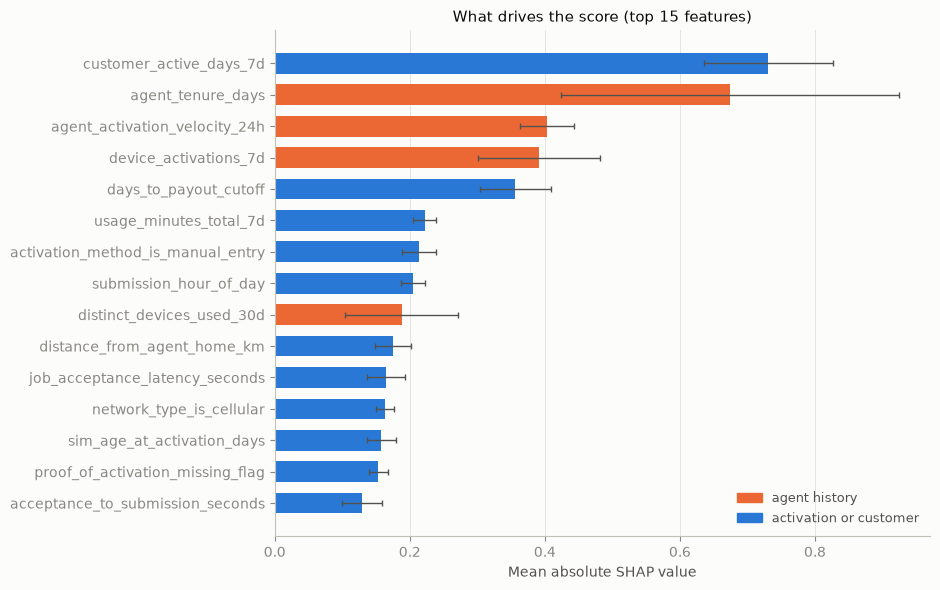

In [16]:
fig, axis = plt.subplots(figsize=(9.5, 6))
top = shap_global.head(15).iloc[::-1]
colours = [SLOTS[1] if group == "agent history" else SLOTS[0] for group in top["group"]]
positions = np.arange(len(top))
axis.barh(positions, top["mean_abs_shap"], height=0.66, color=colours,
          xerr=top["sd_across_seeds"], error_kw={"ecolor": INK_2, "elinewidth": 1.0, "capsize": 2})
axis.set_yticks(positions, top["feature"])
axis.set(xlabel="Mean absolute SHAP value", title="What drives the score (top 15 features)")
axis.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=SLOTS[1]), plt.Rectangle((0, 0), 1, 1, color=SLOTS[0])]
axis.legend(handles, ["agent history", "activation or customer"], fontsize=9, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "shap_global.png", dpi=120)
plt.show()

In [17]:
shap_typology.groupby("typology").head(5)[
    ["typology", "feature", "mean_abs_shap", "mean_signed_shap", "share_within_typology"]].round(4)

,typology,feature,mean_abs_shap,mean_signed_shap,share_within_typology
0,collusion,customer_active_days_7d,0.6736,0.3166,0.1343
1,collusion,agent_activation_velocity_24h,0.5298,0.3110,0.1056
2,collusion,device_activations_7d,0.4690,0.2250,0.0935
3,collusion,days_to_payout_cutoff,0.4044,0.1264,0.0806
4,collusion,agent_tenure_days,0.3468,-0.2108,0.0691
27,ghost,customer_active_days_7d,0.7850,0.6078,0.1303
28,ghost,agent_activation_velocity_24h,0.4811,0.2535,0.0799
29,ghost,activation_method_is_manual_entry,0.4401,0.2702,0.0731
30,ghost,proof_of_activation_missing_flag,0.4274,0.2524,0.0710
31,ghost,agent_tenure_days,0.4273,-0.2268,0.0709


### Three activations, as an admin would see them

Each case is the median-scoring activation of its band, so it is what an admin
typically sees rather than the most extreme row. The reason strings are
generated from the SHAP values by `src/eval/explanations.py`, in the language a
review screen would use rather than feature names.

In [18]:
for _, case in shap_cases.iterrows():
    print(f"[{case['band'].upper()}]  calibrated probability {case['calibrated_probability']:.3f}"
          f"   (actually fraudulent: {case['actually_fraudulent']}, typology: {case['typology']})")
    for reason in case["reason_shown_to_admin"].split("; "):
        print(f"    - {reason}")
    print()

[AUTO-RELEASED]  calibrated probability 0.008   (actually fraudulent: False, typology: none)
    - the customer used the service on 6 of the 8 days after signup (lowers the score)
    - the agent submitted 2 activations in the previous 24 hours (lowers the score)
    - no proof of activation was attached (raises the score)
    - the activation was submitted 11.0 days before a payout cutoff (lowers the score)

[SENT TO REVIEW]  calibrated probability 0.278   (actually fraudulent: False, typology: none)
    - the customer used the service on 0 of the 8 days after signup (raises the score)
    - the agent has been on the platform 110 days (raises the score)
    - this device was used for 35 activations in the last 7 days (raises the score)
    - the activation was 6.7 km from the agent's base (lowers the score)

[REJECTED]  calibrated probability 0.836   (actually fraudulent: False, typology: none)
    - this device was used for 83 activations in the last 7 days (raises the score)
    - t

### Part E4: is the admin being told about the activation or the agent?

The Phase 4 ablation found that removing the six agent-history features cost
0.111 PR-AUC, about a sixth of the performance above the prevalence floor. The
matching question for explanations is what share of the reason they carry.

**Answer: about a third, and it is worse than the performance figure suggests.**
Agent-history features carry **35.6%** of the total explanation mass, against
roughly 16% of the performance. `agent_tenure_days` alone is the second largest
driver in the model at 13.4%, and how long an agent has been on the platform
says nothing whatever about whether this activation is real. The single largest
driver is `customer_active_days_7d`, which is about the activation, so an admin
is not only being told about the agent, but a third of what they are told is
about the person rather than the job.

In [19]:
shap_shares.round(4)

,scope,agent_history_share_of_explanation,top_feature,top_feature_is_agent_history
0,all sampled rows,0.3557,customer_active_days_7d,False
1,fraud: collusion,0.3290,customer_active_days_7d,False
2,fraud: ghost,0.2785,customer_active_days_7d,False
3,fraud: payout_gaming,0.3318,customer_active_days_7d,False
4,fraud: sim_farming,0.2915,customer_active_days_7d,False


## Part F: who the bands hold

Phase 4 measured this at a fixed precision operating point. The bands are now
set by cost, so the question is asked again where the system would really sit.
All of this is restricted to **genuine** activations: work that should have been
paid.

This characterises the problem. It does not fix it.

In [20]:
fair_honesty.pivot_table(index="honesty_type", columns="band",
                         values=["share_mean", "share_sd_across_seeds"]).round(5)

share_mean                   share_sd_across_seeds                  
band          auto-released   reject   review         auto-released   reject   review
honesty_type                                                                         
honest              0.98592  0.00492  0.00916               0.00626  0.00273  0.00364
opportunistic       0.97796  0.00774  0.01430               0.00419  0.00307  0.00304
systematic          0.87286  0.05712  0.07001               0.01322  0.00977  0.01427

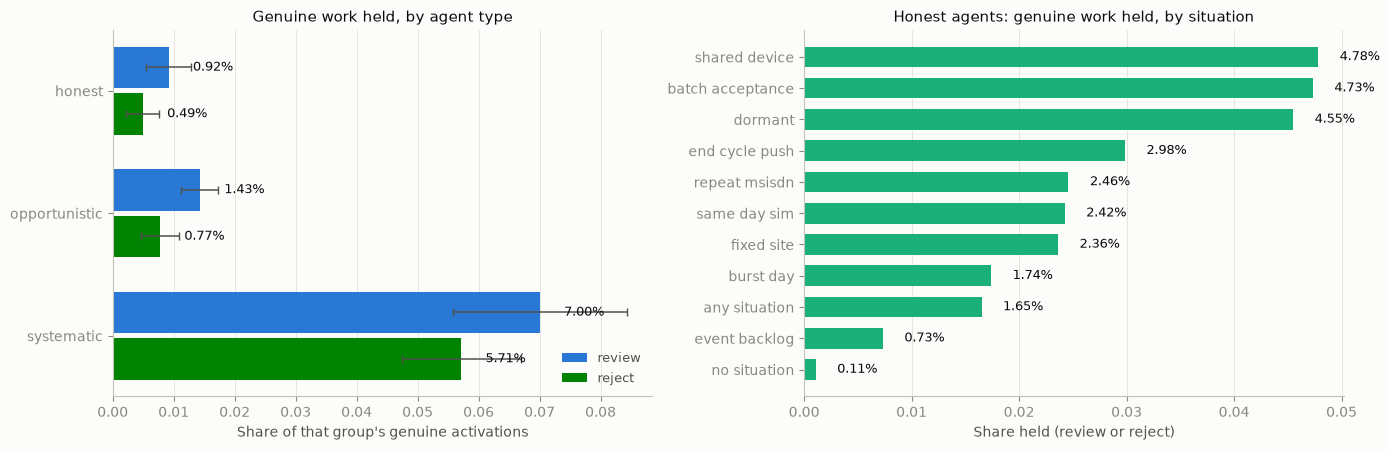

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
order = ["honest", "opportunistic", "systematic"]
bands = ["review", "reject"]
colour = dict(zip(bands, [SLOTS[0], SLOTS[5]]))
pivot = fair_honesty.pivot_table(index="honesty_type", columns="band", values="share_mean").reindex(order)
errors = fair_honesty.pivot_table(index="honesty_type", columns="band", values="share_sd_across_seeds").reindex(order)
base = np.arange(len(order))[::-1]
for offset, band in zip((0.19, -0.19), bands):
    axes[0].barh(base + offset, pivot[band], height=0.34, color=colour[band], label=band,
                 xerr=errors[band], error_kw={"ecolor": INK_2, "elinewidth": 1.1, "capsize": 3})
    for y, value in zip(base + offset, pivot[band]):
        axes[0].text(value + 0.004, y, f"{value:.2%}", va="center", fontsize=9, color=INK)
axes[0].set_yticks(base, order)
axes[0].set(xlabel="Share of that group's genuine activations", title="Genuine work held, by agent type")
axes[0].grid(axis="y", visible=False)
axes[0].legend(fontsize=9, loc="lower right")

honest = fair_situation[(fair_situation["population"] == "honest agents only") & (fair_situation["band"] != "auto-released")]
held = honest.groupby("situation")["share_mean"].sum().sort_values()
positions = np.arange(len(held))
axes[1].barh(positions, held.to_numpy(), height=0.66, color=SLOTS[2])
axes[1].set_yticks(positions, [s.replace("_", " ") for s in held.index])
for y, value in zip(positions, held.to_numpy()):
    axes[1].text(value + 0.002, y, f"{value:.2%}", va="center", fontsize=9, color=INK)
axes[1].set(xlabel="Share held (review or reject)", title="Honest agents: genuine work held, by situation")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "fairness_bands.png", dpi=120)
plt.show()

In [22]:
fair_situation[fair_situation["band"] != "auto-released"].pivot_table(
    index=["population", "situation"], columns="band", values="share_mean").round(5)

band                                       reject   review
population              situation                         
all genuine activations any_situation     0.01413  0.02040
                        batch_acceptance  0.03380  0.04129
                        burst_day         0.01415  0.01993
                        dormant           0.03928  0.05156
                        end_cycle_push    0.02568  0.03243
                        event_backlog     0.00598  0.01313
                        fixed_site        0.00909  0.01453
                        no_situation      0.00126  0.00431
                        repeat_msisdn     0.02049  0.02988
                        same_day_sim      0.01954  0.02245
                        shared_device     0.02077  0.02705
honest agents only      any_situation     0.00576  0.01074
                        batch_acceptance  0.01758  0.02975
                        burst_day         0.00647  0.01092
                        dormant           0.01716  0.02833
                        end_cycle_push    0.01127  0.01857
                        event_backlog     0.00258  0.00474
                        fixed_site        0.00909  0.01453
                        no_situation      0.00054  0.00054
                        repeat_msisdn     0.00845  0.01614
                        same_day_sim      0.00904  0.01520
                        shared_device     0.02077  0.02705

### Part F3: how long the money is held

Waiting time uses an M/D/1 queue (Poisson arrivals, fixed nine-minute reviews).
That is a standard approximation, not a measurement.

**The queue is not where the harm is.** The review band takes 2.5% of volume
against a capacity of 7.9%, so utilisation is 0.32 and the average wait is
0.006 days, about nine minutes. The expected extra delay for a genuine
activation is a fraction of a day for every agent type.

The harm is the reject band, where a genuine activation is not delayed but
refused: 0.49% of honest agents' genuine work and 5.71% of systematic agents'
genuine work. A refusal is not a wait; it is a payout that does not arrive
unless someone appeals.

In [23]:
display(fair_delay.round(4))
fair_queue.round(4)

,honesty_type,auto-released,reject,review,expected_extra_delay_days,share_withheld_pending_appeal,note
0,honest,0.9859,0.0049,0.0092,0.0001,0.0049,review adds 0.01 days on average; a rejected g...
1,opportunistic,0.9780,0.0077,0.0143,0.0001,0.0077,review adds 0.01 days on average; a rejected g...
2,systematic,0.8729,0.0571,0.0700,0.0004,0.0571,review adds 0.01 days on average; a rejected g...


,review_share_of_volume,daily_activations,daily_review_arrivals,daily_review_capacity,utilisation,mean_wait_days_for_a_reviewed_activation,model
0,0.0251,508.996,12.7549,40,0.3189,0.0059,"M/D/1, Poisson arrivals and fixed review time"


## What this session establishes, and what it does not

**Established.**

- The chosen model's probabilities are honest after isotonic calibration (ECE 0.0067), so the bands mean what they say.
- Measured as auto-release volume at a 99% pure released set, the seven-day hold window buys 15.9 points of volume (73.3% against 57.4%), a 27.7% relative gain. That is a much stronger case for the hold than the PR-AUC gap suggested, and it is the metric the hold should be judged on.
- At the cost-optimal bands the system auto-releases 92.5% of volume, reviews 2.5% and refuses 5.0%, at an expected cost of 0.088 commissions per activation against 0.182 for releasing everything untouched.
- Review capacity is not the binding constraint. The optimum uses a third of one reviewer, and adding reviewers changes nothing.

**Not established, and the honest caveats.**

- **The bands are not robust to the cost matrix.** Across the stated ranges the reject threshold moves between 0.13 and 0.75, and the review band disappears entirely at either a cheap false positive or an expensive review. The operating point below is the right answer for one particular cost vector, and that vector contains two numbers nobody has measured.
- **The number to measure first is the cost of a review**, followed by the cost of a wrongly refused payout. Both change the structure of the answer, not just its position. The fraud cost moves the release threshold but never removes a band.
- **Reviews are assumed correct.** Every result that favours the review band depends on it.
- **The cost of a false positive is carried almost entirely by honest agents whose legitimate working patterns resemble fraud.** Honest work with no lookalike situation is held 0.1% of the time; honest work on a shared team device is held 4.8% of the time.